# TP 5 · Diagnostiquer avant de modifier

AI4I 2020. **Validation inchangée**, mais on entraîne sur un **sous-ensemble du train** (documenté ci-dessous), pour rendre l'overfitting visible.

Règle d'or du TP : **une seule modification à la fois**, et **toujours la même validation**. Sinon, impossible de savoir ce qui a produit l'effet.

## 0. Reprise : splits et preprocessing du TP 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import precision_score, recall_score, confusion_matrix

df = pd.read_csv("data/ai4i2020.csv")
TARGET = "Machine failure"
NUM_COLS = ["Torque [Nm]", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Tool wear [min]"]
CAT_COLS = ["Type"]
X = df[NUM_COLS + CAT_COLS]
Y = df[TARGET]

# mêmes splits que les TP 1 et 3 : 60 / 20 / 20, stratifiés
X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.4, stratify=Y, random_state=42)
X_val, X_test, Y_val, Y_test   = train_test_split(X_tmp, Y_tmp, test_size=0.5, stratify=Y_tmp, random_state=42)

# même preprocessing, fit sur train uniquement
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])
preprocess.fit(X_train)
print(len(X_train), len(X_val), len(X_test), "| pannes en validation :", Y_val.sum())

6000 2000 2000 | pannes en validation : 68


### Le sous-ensemble de train (documenté)

- **300 lignes** tirées du train (5 %), **stratifiées** (même taux de pannes), `random_state=0`, comme dans le cours.
- Pourquoi : avec 6000 lignes, un petit réseau overfit très peu. Avec 300 lignes, l'overfitting apparaît clairement et on peut tester des remèdes.
- La **validation reste complète** (2000 lignes), identique aux TP précédents.

In [2]:
X_train_p = preprocess.transform(X_train)
X_s, _, y_s, _ = train_test_split(X_train_p, Y_train.to_numpy(),
                                  train_size=300, stratify=Y_train, random_state=0)
Xs_t = torch.tensor(X_s, dtype=torch.float32)
ys_t = torch.tensor(y_s, dtype=torch.float32)
X_val_t = torch.tensor(preprocess.transform(X_val), dtype=torch.float32)
y_val_t = torch.tensor(Y_val.to_numpy(), dtype=torch.float32)

print("sous-ensemble de train :", tuple(Xs_t.shape), "|", int(ys_t.sum()), "pannes")
print("validation             :", tuple(X_val_t.shape), "|", int(y_val_t.sum()), "pannes")

sous-ensemble de train : (300, 8) | 10 pannes
validation             : (2000, 8) | 68 pannes


## Une fonction d'entraînement commune (budget identique pour tous)

Pour comparer **à budget comparable**, tous les essais utilisent exactement :
- la même seed (42), le même optimizer (Adam), le même **learning rate (1e-2)**, le même nombre d'**epochs (300)** ;
- les 300 lignes passent en un seul batch (comme dans le cours).

La fonction mémorise la loss de train et de validation à chaque epoch, **et le meilleur état** (celui qui a la plus petite loss de validation).

In [3]:
from copy import deepcopy
loss_fn = nn.BCEWithLogitsLoss()
EPOCHS, LR = 300, 1e-2

def mlp(hidden):
    return nn.Sequential(nn.Linear(8, hidden), nn.ReLU(), nn.Linear(hidden, 1))

def train(model, epochs=EPOCHS, lr=LR, **opt_args):
    opt = torch.optim.Adam(model.parameters(), lr=lr, **opt_args)
    hist = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xs_t).squeeze(1), ys_t)
        loss.backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_val_t).squeeze(1), y_val_t).item()
        hist["train"].append(loss.item()); hist["val"].append(val)
        if val < best_val:
            best_val, best_state = val, deepcopy(model.state_dict())
    return hist, best_state

def resume(name, hist):
    best = int(np.argmin(hist["val"]))
    return {"essai": name, "meilleure epoch": best + 1, "val min": hist["val"][best],
            "val finale": hist["val"][-1], "remontée": hist["val"][-1] - hist["val"][best],
            "train final": hist["train"][-1]}

## 1. Comparer un réseau de 8 neurones et un réseau de 64 neurones

Seule différence entre les deux : la **largeur** de la couche cachée (= la **capacité** du modèle).

In [4]:
results, histories, states = [], {}, {}
for name, hidden in [("8 neurones", 8), ("64 neurones", 64)]:
    torch.manual_seed(42)
    m = mlp(hidden)
    histories[name], states[name] = train(m)
    results.append(resume(name, histories[name]))
    print(f"{name:<12} parameters : {sum(p.numel() for p in m.parameters())}")
pd.DataFrame(results).set_index("essai").round(4)

8 neurones   parameters : 81
64 neurones  parameters : 641


,meilleure epoch,val min,val finale,remontée,train final
essai,,,,,
8 neurones,131,0.1071,0.1196,0.0125,0.0346
64 neurones,58,0.1249,0.1703,0.0454,0.0090


## 2. Tracer les losses de train et de validation, à budget comparable

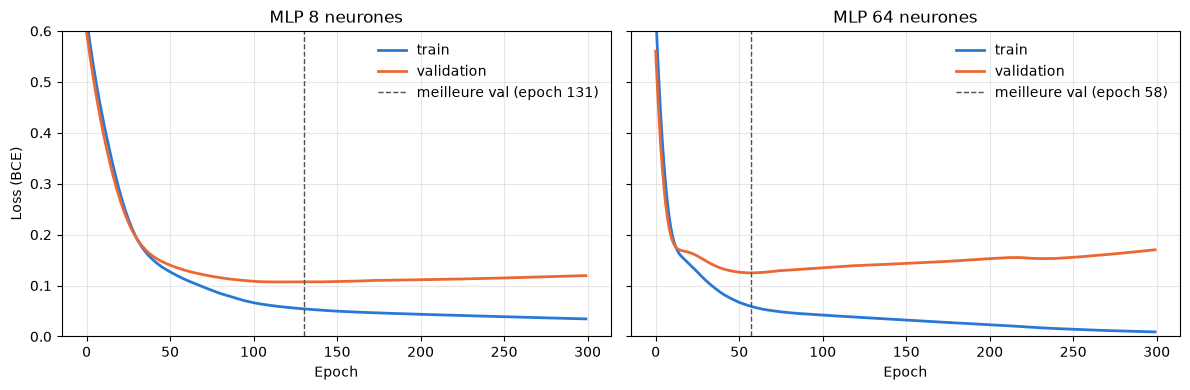

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["8 neurones", "64 neurones"]):
    h = histories[name]
    best = int(np.argmin(h["val"]))
    ax.plot(h["train"], color="#2a78d6", lw=2, label="train")
    ax.plot(h["val"], color="#eb6834", lw=2, label="validation")
    ax.axvline(best, ls="--", color="#52514e", lw=1, label=f"meilleure val (epoch {best + 1})")
    ax.set_title(f"MLP {name}")
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
    ax.legend(frameon=False)
axes[0].set_ylabel("Loss (BCE)")
axes[0].set_ylim(0, 0.6)
plt.tight_layout(); plt.show()

**Diagnostic :**
- **64 neurones** : la loss de train s'effondre vers 0 (il apprend ses 300 lignes **par cœur**), tandis que la validation atteint son minimum très tôt puis **remonte**. C'est la signature de l'**overfitting** : trop de capacité pour 300 lignes (dont seulement ~10 pannes).
- **8 neurones** : la validation descend plus loin et remonte beaucoup moins. Moins de capacité → moins de place pour mémoriser.

Situations à distinguer (cours) :
| Observation | Hypothèse |
|---|---|
| train et val restent mauvais | underfitting, ou bug de pipeline |
| train bon, **val se dégrade** | **overfitting** ← notre cas à 64 neurones |
| résultat parfait immédiatement | data leakage possible |

## 3. Tester un seul levier de regularization : le weight decay

On garde **exactement** le réseau de 64 neurones (même seed, même lr, mêmes epochs) et on change **une seule chose** : `weight_decay=1e-2` dans Adam.

Le weight decay **pénalise les grands poids** à chaque update. Un réseau aux poids plus petits produit une fonction plus « lisse », qui colle moins aux points du train.

In [6]:
torch.manual_seed(42)
m_wd = mlp(64)
histories["64 neurones + weight decay"], states["64 neurones + weight decay"] = train(m_wd, weight_decay=1e-2)
results.append(resume("64 neurones + weight decay", histories["64 neurones + weight decay"]))
recap = pd.DataFrame(results).set_index("essai")
recap.round(4)

,meilleure epoch,val min,val finale,remontée,train final
essai,,,,,
8 neurones,131,0.1071,0.1196,0.0125,0.0346
64 neurones,58,0.1249,0.1703,0.0454,0.0090
64 neurones + weight decay,183,0.1081,0.1083,0.0002,0.0690


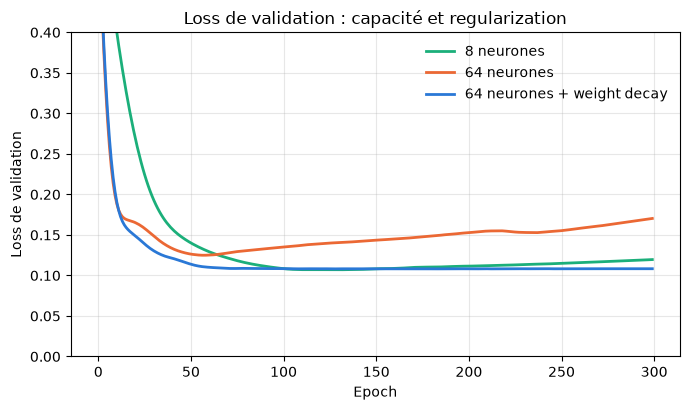

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
colors = {"8 neurones": "#1baf7a", "64 neurones": "#eb6834", "64 neurones + weight decay": "#2a78d6"}
for name, h in histories.items():
    ax.plot(h["val"], color=colors[name], lw=2, label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss de validation")
ax.set_ylim(0, 0.4)
ax.set_title("Loss de validation : capacité et regularization")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Choisir un modèle et expliquer les observations

On compare chaque modèle **à son meilleur état** (meilleure loss de validation), et on regarde aussi precision / recall à un threshold de 0,3 (celui choisi au TP 3).

In [8]:
rows = []
for name, state in states.items():
    hidden = 8 if name.startswith("8") else 64
    m = mlp(hidden); m.load_state_dict(state); m.eval()
    with torch.no_grad():
        s = torch.sigmoid(m(X_val_t).squeeze(1)).numpy()
    p = (s >= 0.3).astype(int)
    rows.append({"essai": name, "val min": recap.loc[name, "val min"],
                 "remontée en fin": recap.loc[name, "remontée"],
                 "precision @0,3": precision_score(Y_val, p, zero_division=0),
                 "recall @0,3": recall_score(Y_val, p)})
pd.DataFrame(rows).set_index("essai").round(3)

,val min,remontée en fin,"precision @0,3","recall @0,3"
essai,,,,
8 neurones,0.107,0.013,0.456,0.382
64 neurones,0.125,0.045,0.290,0.265
64 neurones + weight decay,0.108,0.000,0.500,0.279


## Conclusion

**Observations**
- **64 neurones sans regularization** : overfitting net. La loss de train tombe à 0,009 (le modèle a appris ses 300 lignes par cœur), la validation touche son minimum à l'epoch 58 (0,125) puis remonte à 0,170.
- **8 neurones** : moins de capacité, **meilleure loss de validation** (0,107 à l'epoch 131) et remontée faible (+0,013). Réduire la taille est déjà une forme de regularization.
- **64 neurones + weight decay** (un seul changement) : la validation **ne remonte plus du tout** (+0,000) et atteint 0,108, presque comme le petit réseau. Le weight decay a supprimé l'overfitting sans réduire l'architecture.

**Choix : le réseau de 8 neurones, à son meilleur état (epoch 131).**
- Meilleure loss de validation (0,107), et aussi le **meilleur recall** au threshold 0,3 (38 % contre 28 % pour les deux réseaux de 64).
- Le plus **simple** : 81 parameters contre 641.
- Sa légère remontée en fin d'entraînement n'est pas un problème, puisqu'on **conserve le meilleur état** choisi sur la validation (principe de l'early stopping).
- Le 64 + weight decay est un bon second : aussi bon en loss et parfaitement stable, mais plus gros et moins bon en recall ici.

**Limites**
- Le sous-ensemble ne contient que **10 pannes** : les écarts de precision / recall entre modèles reposent sur très peu d'exemples (une panne de plus ou de moins sur 68 en validation = 1,5 point de recall).
- Une seule seed : le cours montre que la seed seule fait varier le recall de plusieurs points. Il faudrait répéter sur 5 seeds avant de conclure fermement.
- Ce diagnostic porte sur 300 lignes : avec le train complet (TP 6), l'overfitting est beaucoup moins marqué et un réseau plus large redevient intéressant.